In [13]:
import pandas as pd

before = pd.read_csv("evaluation_before2.csv")
after = pd.read_csv("evaluation_after2.csv")

print("Before columns:", before.columns.tolist())
print("After columns:", after.columns.tolist())

Before columns: ['user_input', 'retrieved_contexts', 'response', 'reference', 'faithfulness', 'answer_relevancy', 'context_precision', 'ground_truth_consistency']
After columns: ['user_input', 'retrieved_contexts', 'response', 'reference', 'faithfulness', 'answer_relevancy', 'context_precision', 'ground_truth_consistency']


In [14]:
import pandas as pd

before = pd.read_csv("evaluation_before2.csv")
after = pd.read_csv("evaluation_after2.csv")

# Colonnes numériques candidates (exclure question, answer, contexts, etc.)
num_cols_before = before.select_dtypes(include=["float64", "float32", "int64", "int32"]).columns.tolist()
num_cols_after = after.select_dtypes(include=["float64", "float32", "int64", "int32"]).columns.tolist()

# Garder uniquement les colonnes présentes dans les deux
common_metrics = sorted(set(num_cols_before) & set(num_cols_after))

# Optionnel : filtrer si tu veux exclure certaines colonnes non-métriques
# common_metrics = [c for c in common_metrics if c not in {"question_id", "latency_ms"}]

comparison = pd.DataFrame(
    {
        "metric": common_metrics,
        "before": [before[m].mean() for m in common_metrics],
        "after": [after[m].mean() for m in common_metrics],
    }
)

comparison["delta"] = comparison["after"] - comparison["before"]
comparison["relative_change_pct"] = (
    comparison["delta"] / comparison["before"] * 100
)

comparison.to_csv("comparison.csv", index=False)
print(comparison)

                     metric  before  after  delta  relative_change_pct
0          answer_relevancy     0.2    0.4    0.2                100.0
1         context_precision     0.0    0.4    0.4                  inf
2              faithfulness     0.0    0.2    0.2                  inf
3  ground_truth_consistency     0.8    1.0    0.2                 25.0


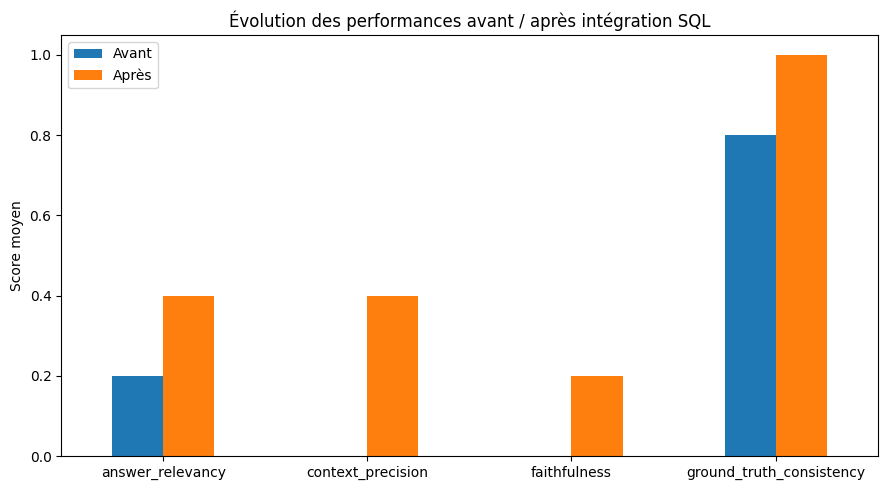

In [15]:
import matplotlib.pyplot as plt
import pandas as pd

comparison = pd.read_csv("comparison.csv")

ax = comparison.plot(
    x="metric",
    y=["before", "after"],
    kind="bar",
    figsize=(9, 5),
    rot=0,
)

ax.set_ylabel("Score moyen")
ax.set_xlabel("")
ax.set_title("Évolution des performances avant / après intégration SQL")
ax.legend(["Avant", "Après"])
plt.tight_layout()
plt.savefig("performance_comparison.png", dpi=150)